In [1]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, Image

### Funkcje pomocnicze

Przy wczytywaniu sudoku z pliku, wypełniam puste miejsca unikalnymi w danym bloku cyframi. Tworzę też dodatkowe struktury, ułatwiające później wizualizację i zamienianie liczb miejscami, takie jak tablica z indeksami liczb zczytanych z pliku, oraz tablica z pustymi indeksami w każdym bloku.

In [11]:
DATA_PATH = "zad3_files/"

def load(name):
    sudoku = np.zeros(shape=(9, 9), dtype=np.int8)
    nums = [[False for _ in range(10)] for _ in range(9)]
    nums_itr = [1 for _ in range(9)]
    free_pos = [[] for _ in range(9)]
    fixed_pos = []

    with open(f"{DATA_PATH}{name}.su", "r") as file:
        for i, line in enumerate(file):
            x = 6 if i >= 6 else (3 if i >= 3 else 0)
            for j, char in enumerate(line):
                y = 2 if j >= 6 else (1 if j >= 3 else 0)

                if char.isdigit():
                    n = int(char)
                    sudoku[i, j] = n
                    nums[x + y][n] = True
                    fixed_pos.append((i, j))
                elif char == 'x': free_pos[x + y].append((i, j))

    for i in range(9):
        x = 6 if i >= 6 else (3 if i >= 3 else 0)
        for j in range(9):
            y = 2 if j >= 6 else (1 if j >= 3 else 0)
            if sudoku[i, j] == 0:
                while nums[x + y][nums_itr[x + y]]: nums_itr[x + y] += 1
                sudoku[i, j] = nums_itr[x + y]
                nums_itr[x + y] += 1

    return sudoku, list(filter(lambda x: len(x) > 1, free_pos)), fixed_pos

def plot_sudoku(sudoku, fixed_pos):
    fig, ax = plt.subplots(figsize=(6, 6))
    
    ax.set_xlim(0, 9)
    ax.set_ylim(9, 0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect('equal')

    for i in range(10):
        lw = 3 if i % 3 == 0 else 1
        ax.axhline(i, c='black', lw=lw)
        ax.axvline(i, c='black', lw=lw)

    rows = np.zeros(shape=(9, 10), dtype=np.int8)
    cols = np.zeros(shape=(9, 10), dtype=np.int8)
    for i in range(9):
        for j in range(9):
            rows[i, sudoku[i, j]] += 1
            cols[j, sudoku[i, j]] += 1

    colors = np.zeros(shape=(9, 9), dtype=np.int8)
    for i in range(9):
        for j in range(9):
            if rows[i, sudoku[i, j]] > 1: colors[i, j] = 2
            elif cols[j, sudoku[i, j]] > 1: colors[i, j] = 2

    for x, y in fixed_pos: colors[x, y] = 1

    for i in range(9):
        for j in range(9):
                color = "black" if colors[i, j] == 1 else ("green" if colors[i, j] == 0 else "red")
                ax.text(j + 0.5, i + 0.5, int(sudoku[i, j]), 
                        ha='center', va='center', c=color,
                        fontsize=16, fontweight='bold')

    plt.show()

def plot_result(energy, temperature):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = len(energy)
    x = [i for i in range(epochs)]

    axes[0].plot(x, energy)
    axes[0].set_title("Wykres energii")
    axes[0].set_xlabel("Kroki")
    axes[0].set_ylabel("Energia")

    axes[1].plot(x, temperature)
    axes[1].set_title("Wykres temperatury")
    axes[1].set_xlabel("Kroki")
    axes[1].set_ylabel("Temperatura")

    plt.show()

def gif_sudoku(steps, fixed_pos, name):
    fig, ax = plt.subplots(figsize=(6, 6))

    def update(ind):
        ax.clear()
        ax.set_xlim(0, 9)
        ax.set_ylim(9, 0)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_aspect('equal')

        for i in range(10):
            lw = 3 if i % 3 == 0 else 1
            ax.axhline(i, c='black', lw=lw)
            ax.axvline(i, c='black', lw=lw)

        rows = np.zeros(shape=(9, 10), dtype=np.int8)
        cols = np.zeros(shape=(9, 10), dtype=np.int8)
        for i in range(9):
            for j in range(9):
                rows[i, steps[ind][i, j]] += 1
                cols[j, steps[ind][i, j]] += 1

        colors = np.zeros(shape=(9, 9), dtype=np.int8)
        for i in range(9):
            for j in range(9):
                if rows[i, steps[ind][i, j]] > 1: colors[i, j] = 2
                elif cols[j, steps[ind][i, j]] > 1: colors[i, j] = 2

        for x, y in fixed_pos: colors[x, y] = 1

        for i in range(9):
            for j in range(9):
                    color = "black" if colors[i, j] == 1 else ("green" if colors[i, j] == 0 else "red")
                    ax.text(j + 0.5, i + 0.5, int(steps[ind][i, j]), 
                            ha='center', va='center', c=color,
                            fontsize=16, fontweight='bold')

    n = len(steps)
    ani = FuncAnimation(fig, update, frames=n, interval=200, blit=False)
    ani.save(f"{DATA_PATH}{name}.gif", writer="pillow")

    plt.close(fig)

def display_image(name):
    display(Image(filename=f"{DATA_PATH}{name}"))

### Kod wyrzażania

Energię wyliczam tak jak w poleceniu. Kolejne permutacje generowane są, losując jeden z bloków, który ma conajmniej 2 niewypełnione z pliku pola, a następnie losuje z bloku 2 cyfry które zamienie miejscami.

In [12]:
def count_energy(sudoku):
    blocks = np.zeros(shape=(9, 10), dtype=np.int8)
    rows = np.zeros(shape=(9, 10), dtype=np.int8)
    cols = np.zeros(shape=(9, 10), dtype=np.int8)

    # nie trzeba sprawdzac blokow, bo w moim swap zawsze sa poprawne
    # ale dla zasady sprawdzam i tak
    energy = 0
    for i in range(9):
        x = 6 if i >= 6 else (3 if i >= 3 else 0)
        for j in range(9):
            y = 2 if j >= 6 else (1 if j >= 3 else 0)
            
            blocks[x + y, sudoku[i, j]] += 1
            rows[i, sudoku[i, j]] += 1
            cols[j, sudoku[i, j]] += 1

            if blocks[x + y, sudoku[i, j]] > 1: energy += 1
            if rows[i, sudoku[i, j]] > 1: energy += 1
            if cols[j, sudoku[i, j]] > 1: energy += 1

    return energy

def arb_swap(free_pos):
    n = len(free_pos)
    block = free_pos[np.random.randint(0, n)]
    m = len(block)

    i1 = np.random.randint(0, m)
    block[m - 1], block[i1] = block[i1], block[m - 1]

    i2 = np.random.randint(0, m - 1)
    return block[m - 1], block[i2]

def exp_cooling(T, start_temperature, epoch, epochs):
    return 0.95 * T

def lin_cooling(T, start_temperature, epoch, epochs):
    return max(T - start_temperature / epochs, 0)

def log_cooling(T, start_temperature, epoch, epochs):
    return start_temperature / np.log(np.e + epoch + 1)

def count_p(T, deltaE):
    return np.exp(-deltaE / T)

def simulated_annealing(sudoku, free_pos, epochs, start_temperature, cooling_function):
    E = count_energy(sudoku)
    T = start_temperature

    steps = []
    steps.append(sudoku.copy())

    energy = []
    temperature = []
    for epoch in range(epochs):
        temperature.append(T)
        energy.append(E)

        a, b = arb_swap(free_pos)
        sudoku[a[0], a[1]], sudoku[b[0], b[1]] = sudoku[b[0], b[1]].copy(), sudoku[a[0], a[1]].copy()
        deltaE = count_energy(sudoku) - E

        if deltaE < 0 or count_p(T, deltaE) > np.random.random():
            steps.append(sudoku.copy())
            E += deltaE
        else: sudoku[a[0], a[1]], sudoku[b[0], b[1]] = sudoku[b[0], b[1]].copy(), sudoku[a[0], a[1]].copy()

        T = cooling_function(T, start_temperature, epoch, epochs)
        if T == 0: break

    return energy, temperature, steps

### Próba rozwiązania kilku trudniejszych sudoku

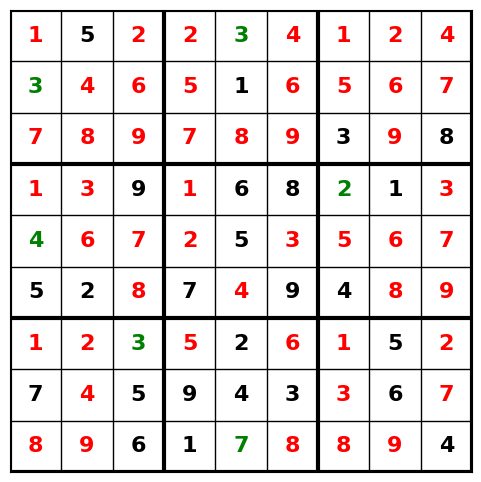

In [29]:
name = 'sudoku1'
sudoku, free_pos, fixed_pos = load(name)
plot_sudoku(sudoku, fixed_pos)

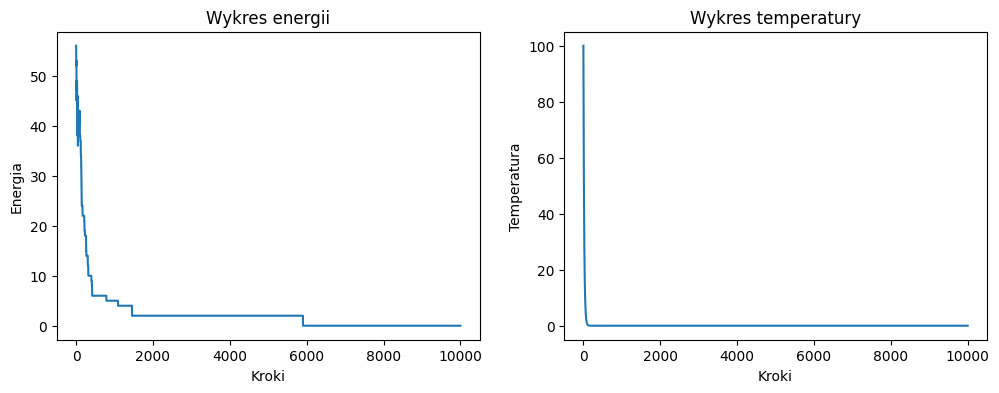

STATUS: ROZWIĄZANE, KOŃCOWA ENERGIA: 0


In [30]:
cooling_function = exp_cooling
start_temperature = 100
epochs = 10000

energy, temperature, steps = simulated_annealing(sudoku, free_pos, epochs, start_temperature, cooling_function)
plot_result(energy, temperature)
print(f"STATUS: {"ROZWIĄZANE" if energy[-1] == 0 else "NIEROZWIĄZANE"}, KOŃCOWA ENERGIA: {energy[-1]}")

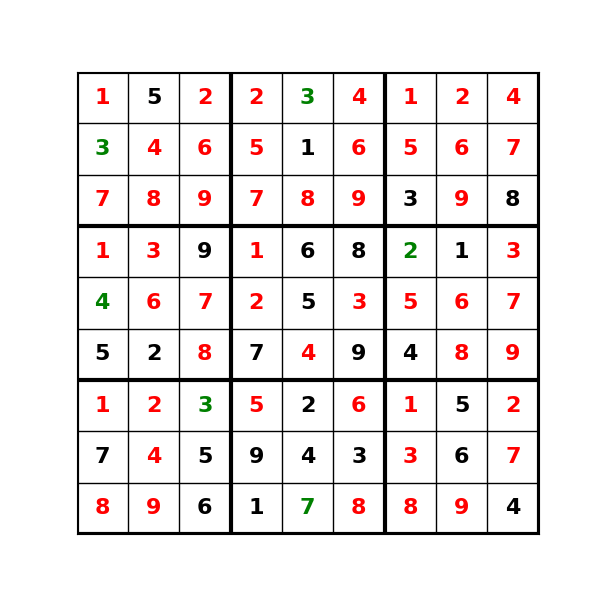

In [32]:
display_image('sudoku1.gif')

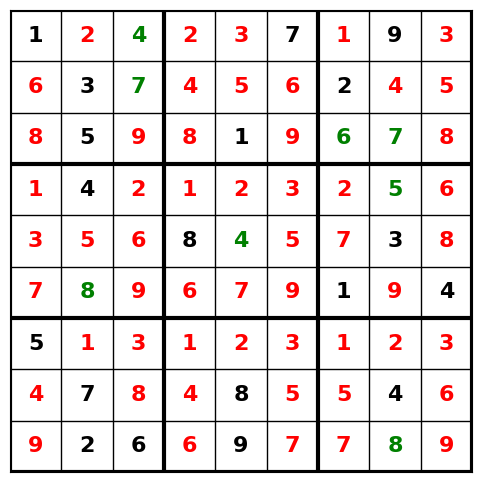

In [35]:
name = 'sudoku2'
sudoku, free_pos, fixed_pos = load(name)
plot_sudoku(sudoku, fixed_pos)

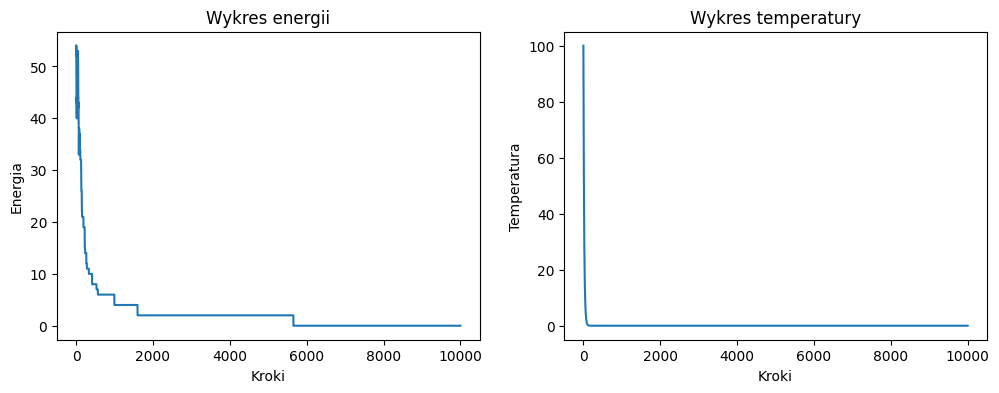

STATUS: ROZWIĄZANE, KOŃCOWA ENERGIA: 0


In [36]:
cooling_function = exp_cooling
start_temperature = 100
epochs = 10000

energy, temperature, steps = simulated_annealing(sudoku, free_pos, epochs, start_temperature, cooling_function)
plot_result(energy, temperature)
print(f"STATUS: {"ROZWIĄZANE" if energy[-1] == 0 else "NIEROZWIĄZANE"}, KOŃCOWA ENERGIA: {energy[-1]}")

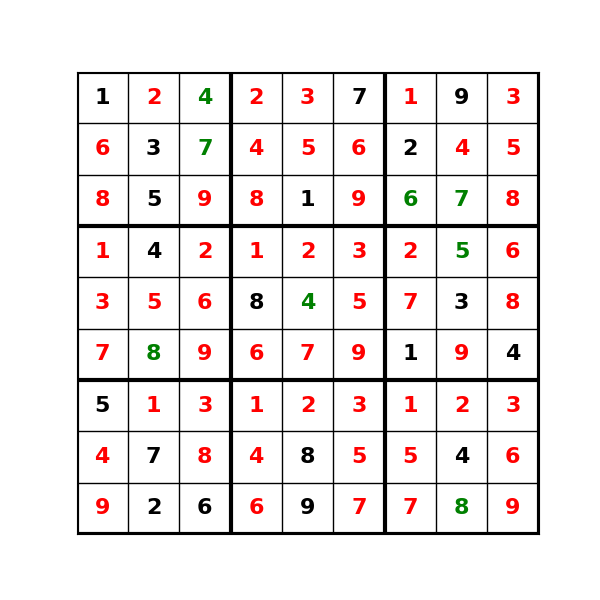

In [39]:
display_image('sudoku2.gif')

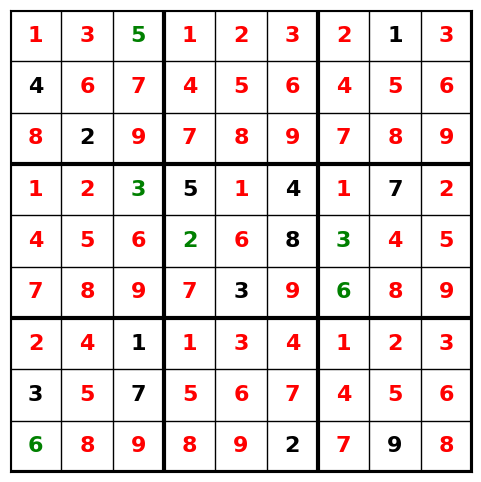

In [46]:
name = 'sudoku3'
sudoku, free_pos, fixed_pos = load(name)
plot_sudoku(sudoku, fixed_pos)

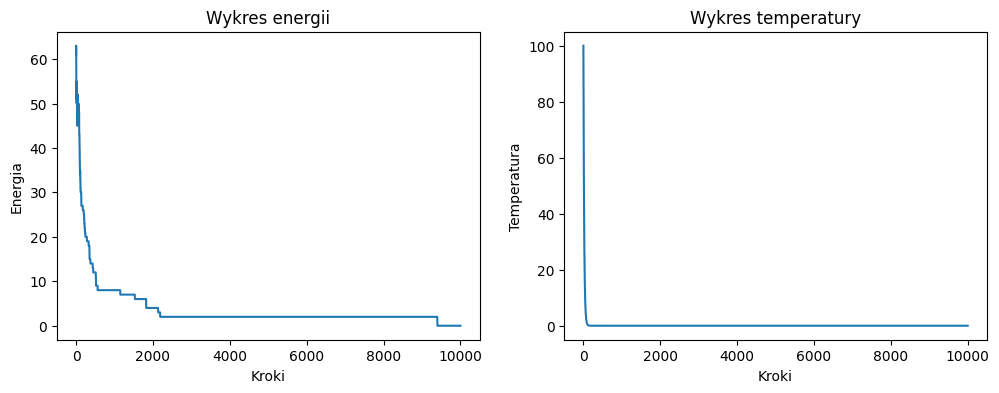

STATUS: ROZWIĄZANE, KOŃCOWA ENERGIA: 0


In [47]:
cooling_function = exp_cooling
start_temperature = 100
epochs = 10000

energy, temperature, steps = simulated_annealing(sudoku, free_pos, epochs, start_temperature, cooling_function)
plot_result(energy, temperature)
print(f"STATUS: {"ROZWIĄZANE" if energy[-1] == 0 else "NIEROZWIĄZANE"}, KOŃCOWA ENERGIA: {energy[-1]}")

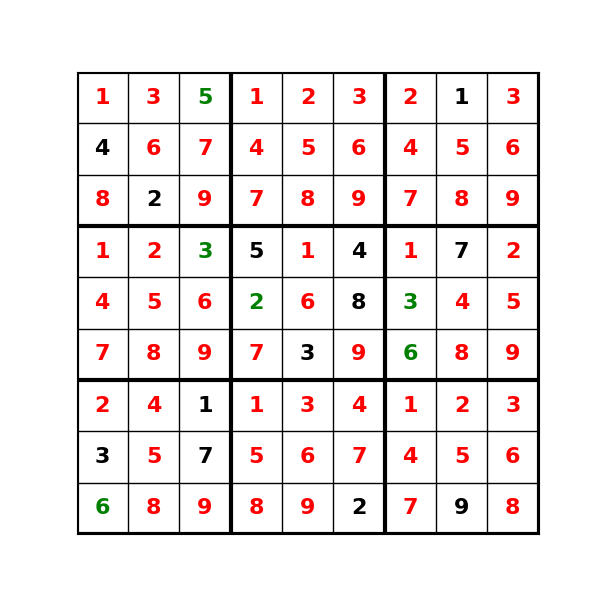

In [51]:
display_image('sudoku3.gif')

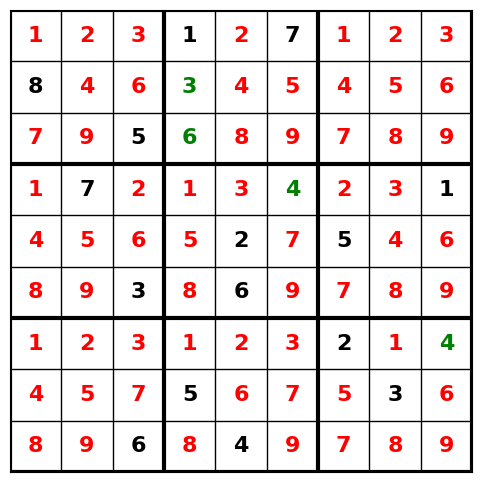

In [54]:
name = 'sudoku4'
sudoku, free_pos, fixed_pos = load(name)
plot_sudoku(sudoku, fixed_pos)

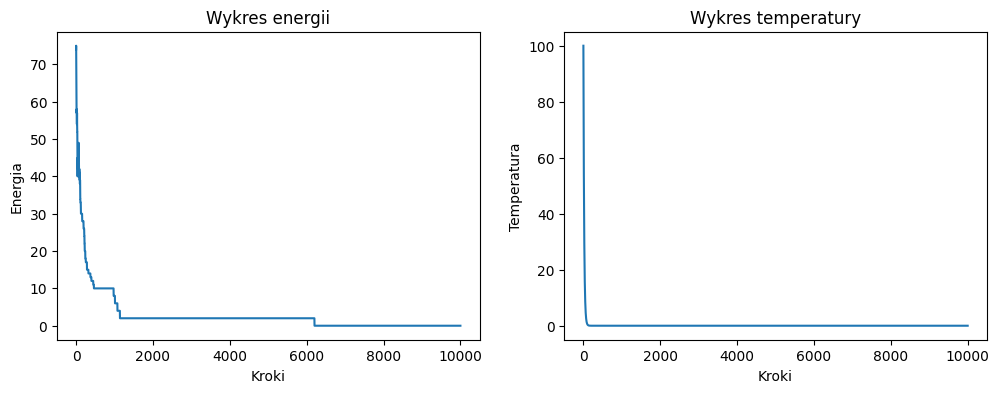

STATUS: ROZWIĄZANE, KOŃCOWA ENERGIA: 0


In [55]:
cooling_function = exp_cooling
start_temperature = 100
epochs = 10000

energy, temperature, steps = simulated_annealing(sudoku, free_pos, epochs, start_temperature, cooling_function)
plot_result(energy, temperature)
print(f"STATUS: {"ROZWIĄZANE" if energy[-1] == 0 else "NIEROZWIĄZANE"}, KOŃCOWA ENERGIA: {energy[-1]}")

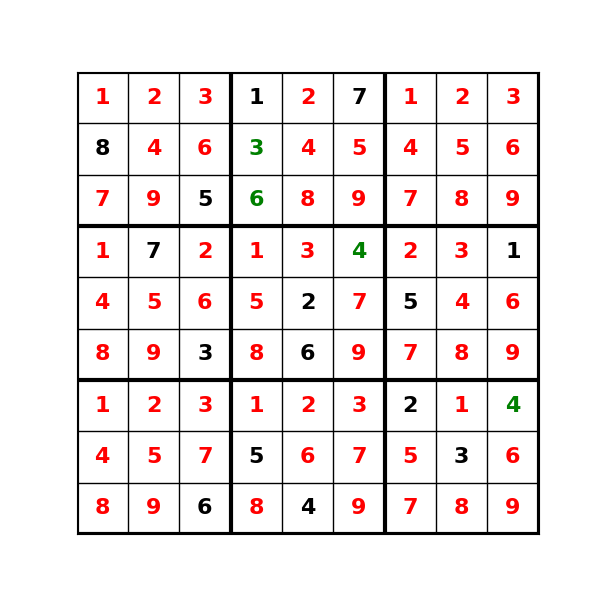

In [58]:
display_image('sudoku4.gif')

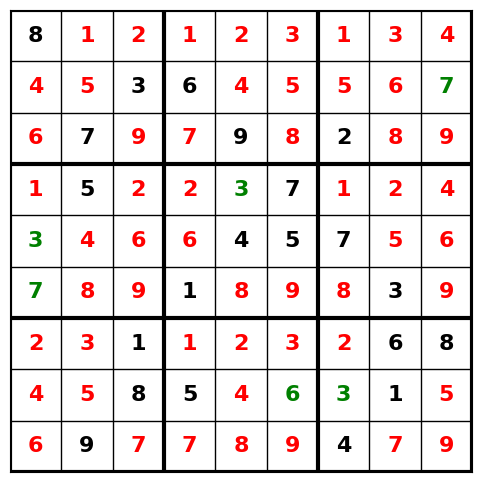

In [116]:
name = 'sudoku5'
sudoku, free_pos, fixed_pos = load(name)
plot_sudoku(sudoku, fixed_pos)

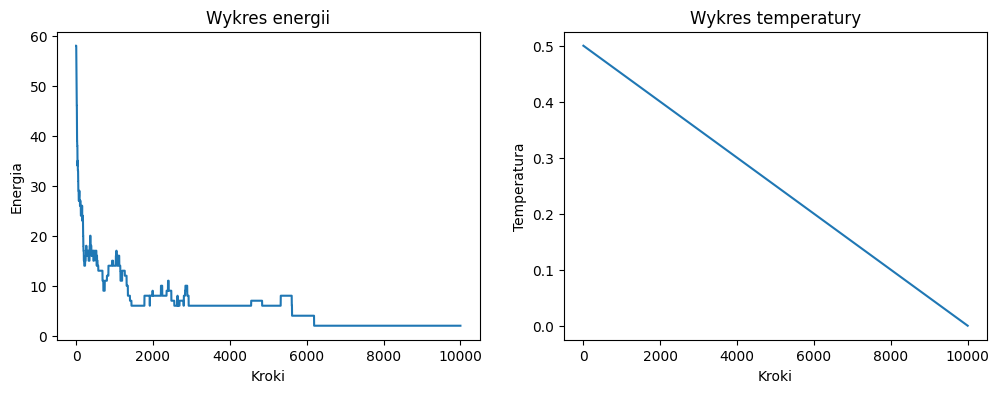

STATUS: NIEROZWIĄZANE, KOŃCOWA ENERGIA: 2


In [117]:
cooling_function = lin_cooling
start_temperature = 0.5
epochs = 10000

energy, temperature, steps = simulated_annealing(sudoku, free_pos, epochs, start_temperature, cooling_function)
plot_result(energy, temperature)
print(f"STATUS: {"ROZWIĄZANE" if energy[-1] == 0 else "NIEROZWIĄZANE"}, KOŃCOWA ENERGIA: {energy[-1]}")

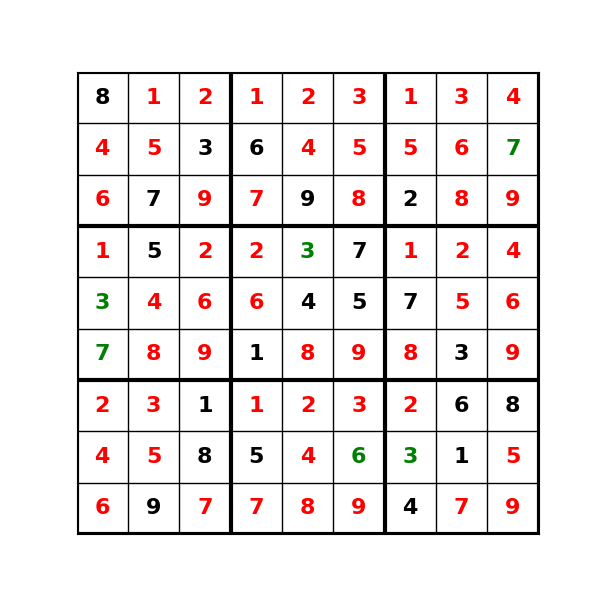

In [120]:
display_image('sudoku5.gif')

### Wnioski

4 pierwsze sudoku rozwiązywane są bez problemu po maks paru próbach, natomiast piąty zestaw okazał się nie do rozwiązania dla wielu testowanych zestawów hiperparametrów. Najlepszy wynik jaki udało się uzyskać przy 5 sudoku to energia = 2. Zestaw ten sprawia że algorytm błądzi w kierunku minimum lokalnego i nie jest w stanie znaleźć minimum globalnego.